# Hielo v1 · ¿Coinciden tres instrumentos de LRO en el hielo del polo sur lunar?

**Proyecto:** Pathfinders42 · NASA Space Apps Challenge 2026 (análogos terrestres de la Luna y Marte).
**Capa anterior:** `hielo_v0` (solo Diviner PRP para la Luna).
**Recursos oficiales del reto que usa:** *NASA LRO* y *LRO Diviner* (PDS Geosciences).

## Para qué sirve este notebook

En `hielo_v0` la presencia de hielo en los sitios lunares se decidió con **un solo instrumento**: Diviner, que
mide temperaturas. Con eso emparejamos, por ejemplo, **Nobile Rim 1 ↔ Pamir** o **IM-1 Odysseus ↔ Axel Heiberg**.

Un solo instrumento es una prueba débil. Aquí añadimos **dos pruebas independientes** del mismo satélite (LRO),
que miden cosas físicas distintas:

| Instrumento | Qué mide | Qué nos dice del hielo |
|---|---|---|
| **Diviner PRP** (ya lo teníamos) | Temperatura de la superficie y del subsuelo | Si hace **suficiente frío** para que el hielo sea estable |
| **Mini-RF** (radar, nuevo) | Cómo se despolariza un eco de radar (CPR) | Si hay algo que **dispersa el radar como el hielo** (aunque la rugosidad hace lo mismo) |
| **LEND** (neutrones, nuevo) | Cuántos neutrones epitérmicos escapan | Si hay **hidrógeno** en el primer metro del suelo |

La pregunta del notebook: **¿en qué sitios coinciden las tres pruebas?** Un sitio donde coinciden dos o tres
instrumentos tiene una pareja de hielo mucho más sólida que uno donde solo lo dice Diviner.

## Qué produce
- `04_resultados/hielo_v1/hielo_lro_sitios.csv`: una fila por sitio polar con las tres pruebas.
- `04_resultados/hielo_v1/figuras/`: mapas del polo sur con los sitios.
- `04_resultados/hielo_v1/registro_hielo_v1.json`: parámetros, fuentes y conteos de la ejecución.
- `06_web/hielo_v1/hielo_lro.json`: la capa para la API (y, opcionalmente, su entrada en `manifest.json`).

## Cómo usarlo
1. Ejecuta las celdas en orden (*Entorno de ejecución → Ejecutar todas*). Tarda unos minutos: descarga ~50 MB.
2. Las descargas se guardan en `03_datos/cache_api/hielo_lro/`; la segunda vez no se vuelve a descargar nada.
3. Al final hay una sección de **conclusiones** vacía: se rellena después de mirar los resultados.

## Glosario rápido

- **PSR** (*permanently shadowed region*): zona que nunca recibe luz del Sol. En los polos de la Luna hay
  cráteres cuyo fondo lleva miles de millones de años a menos de −160 °C: trampas frías para el agua.
- **Hielo estable (Diviner PRP)**: Diviner calcula a qué profundidad la temperatura es lo bastante baja para
  que el hielo no se sublime. `f_hielo` es la fracción del sitio donde eso pasa cerca de la superficie.
- **Radar de apertura sintética (SAR)**: radar que forma imágenes. Mini-RF emite en banda S (12,6 cm).
- **CPR** (*circular polarization ratio*): cociente entre el eco con el **mismo sentido** de polarización que el
  emitido (SC) y el de **sentido opuesto** (OC). Una superficie lisa devuelve casi todo en OC (CPR ≈ 0,2–0,4).
  El hielo enterrado devuelve mucho SC por dispersión de volumen (CPR > 1). **Pero** una superficie llena de
  bloques del tamaño de la longitud de onda también da CPR > 1. Esa ambigüedad es la gran limitación de Mini-RF.
- **Neutrones epitérmicos**: los rayos cósmicos golpean el suelo y arrancan neutrones. El hidrógeno los frena
  muy bien (tiene la misma masa que un neutrón, como dos bolas de billar iguales). Si hay hidrógeno, escapan
  **menos** neutrones epitérmicos: lo que se mide es una **supresión** del flujo.
- **Supresión (%)** = (1 − tasa del sitio / tasa de referencia) × 100. La referencia es una zona seca de
  latitud media (55–60° S, 240–300° E), como en los artículos del equipo de LEND.
- **CSETN**: los cuatro detectores **colimados** de LEND (miran hacia abajo, con un campo de visión estrecho).
  Son los que dan resolución espacial, pero reciben mucho fondo de neutrones de la propia nave.
- **ALD** (*Averaged LEND Data*): producto de PDS con las tasas de LEND ya promediadas en una rejilla. Para el polo
  sur es una rejilla de 0,5° × 0,5° por debajo de −80°.
- **Percentil frente al polo**: comparamos cada sitio con 2000 discos del mismo tamaño puestos al azar en el
  casquete polar (≤ −80°). Percentil 90 = el sitio supera al 90 % de los lugares del polo. Es el mismo enfoque
  de percentiles que usamos en clima.
- **Proyección estereográfica polar**: cerca del polo, latitud y longitud deforman mucho (a −88° un grado de
  longitud mide solo 1 km). Para medir distancias y áreas pasamos todo a un plano centrado en el polo, en km.

## 1. Entorno, rutas y parámetros

In [1]:
import json
import math
import os
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats
from scipy.spatial import cKDTree
from shapely import contains_xy
from shapely.geometry import Point, Polygon

try:  # En Colab montamos Drive; fuera de Colab se usa la variable HACKATHON_BASE
    from google.colab import drive

    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/Hackathon Nasa")
except ImportError:
    BASE = Path(os.environ.get("HACKATHON_BASE", ".")).resolve()

WEB = BASE / "06_web"
CACHE = BASE / "03_datos" / "cache_api" / "hielo_lro"
RES = BASE / "04_resultados" / "hielo_v1"
FIG = RES / "figuras"
for carpeta in (CACHE, FIG, WEB / "hielo_v1"):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Base del proyecto:", BASE)
print("¿Existe 06_web/sitios_v0/sitios.geojson?", (WEB / "sitios_v0" / "sitios.geojson").exists())
print("¿Existe 06_web/hielo_v0/hielo.json?", (WEB / "hielo_v0" / "hielo.json").exists())

Mounted at /content/drive
Base del proyecto: /content/drive/MyDrive/Hackathon Nasa
¿Existe 06_web/sitios_v0/sitios.geojson? True
¿Existe 06_web/hielo_v0/hielo.json? True


**Parámetros.** Están todos aquí para poder cambiarlos sin tocar el resto del código.

- `RADIO_PUNTO_KM`: radio del disco que representa un sitio puntual (IM-1, IM-2, Chang'e 7). Las regiones Artemis
  ya son polígonos de ~400 km² (equivalen a un disco de ~11 km), así que 10 km deja los dos tipos comparables.
- `RADIO_LEND_KM`: LEND ve una mancha de ~10–20 km en el suelo y su rejilla es de 0,5° (~15 km). Promediar a menos
  de 20 km sería fingir una resolución que el instrumento no tiene.
- `PCT_SENAL`: percentil a partir del cual una prueba cuenta como «señal» (75 = cuartil superior del polo).
- `Z_LEND`: además del percentil, la supresión de LEND tiene que ser al menos 2 veces su error estadístico.
- `UMBRAL_HIELO`: el mismo que en `hielo_v0` para Diviner (0,25).

In [2]:
R_LUNA_KM = 1737.4          # radio medio de la Luna
LAT_CASQUETE = -80.0        # trabajamos por debajo de −80° (es el límite de la rejilla polar de LEND)
RADIO_PUNTO_KM = 10.0
RADIO_LEND_KM = 20.0
RADIO_ANILLO_KM = (10.0, 30.0)  # anillo de contexto alrededor de cada sitio (Mini-RF)
N_DISCOS_AZAR = 2000
SEMILLA = 42
PCT_SENAL = 75
Z_LEND = 2.0
UMBRAL_HIELO = 0.25
CPR_VALIDO = (0.0, 5.0)     # fuera de este rango, el píxel se descarta (relleno o ruido)
ACTUALIZAR_MANIFEST = True  # registra la capa «hielo_lro» en 06_web/manifest.json

PDS = "https://pds-geosciences.wustl.edu/lro"
URL_MINIRF_CPR = f"{PDS}/lro-l-mrflro-5-global-mosaic-v1/lromrf_1001/data/32ppd/global_cpr_32ppd_simp_0c.img"
URL_MINIRF_LBL = URL_MINIRF_CPR.replace(".img", ".lbl")
LEND_DATA = f"{PDS}/lro-l-lend-2-edr-v1/lrolen_0xxx/data"
PERIODOS_LEND = {  # fecha de inicio del producto -> carpeta del día en PDS
    "20090915": f"{LEND_DATA}/2009/20090915",  # órbita circular de ~50 km (sep 2009 – dic 2011)
    "20111211": f"{LEND_DATA}/2011/20111211",  # órbita elíptica, periapsis bajo sobre el polo sur (dic 2011 – sep 2016)
}
URL_LEND_FMT = f"{PDS}/lro-l-lend-2-edr-v1/lrolen_0xxx/label/lend_rdr_ald.fmt"

## 2. Los sitios polares y lo que ya sabíamos (Diviner, `hielo_v0`)

Cogemos los sitios lunares de `sitios_v0` por debajo de −80° y les unimos lo que calculó `hielo_v0`:
`f_hielo` (Diviner) y la mejor pareja de la Tierra por hielo y terreno (`region_ht`). Así, al final, cada fila
dice no solo «hay hielo» sino **qué pareja Tierra ↔ Luna queda reforzada o debilitada**.

In [3]:
sitios_geo = json.loads((WEB / "sitios_v0" / "sitios.geojson").read_text(encoding="utf-8"))
hielo_v0 = json.loads((WEB / "hielo_v0" / "hielo.json").read_text(encoding="utf-8"))

filas = []
for f in sitios_geo["features"]:
    p = f["properties"]
    if p["cuerpo"] != "luna":
        continue
    h = hielo_v0["sitios"].get(p["id"], {})
    lat = h.get("lat", p.get("lat_centro"))
    lon = h.get("lon", p.get("lon_centro"))
    if lat is None or lat > LAT_CASQUETE:
        continue
    filas.append(
        {
            "sitio_id": p["id"],
            "nombre": p["nombre"],
            "tipo": p["tipo"],
            "lat": lat,
            "lon": lon,
            "geometria": f["geometry"],
            "diviner_f_hielo": h.get("f_hielo"),
            "diviner_prof_hielo": h.get("hielo_prof"),
            "pareja_hielo_tierra": h.get("region_ht"),
            "analogo_hielo_terreno_v0": h.get("analogo_hielo_terreno"),
        }
    )

sitios = pd.DataFrame(filas).sort_values("lat").reset_index(drop=True)
print(f"{len(sitios)} sitios lunares por debajo de {LAT_CASQUETE}°")
sitios[["sitio_id", "nombre", "lat", "lon", "diviner_f_hielo", "pareja_hielo_tierra", "analogo_hielo_terreno_v0"]]

12 sitios lunares por debajo de -80.0°


,sitio_id,nombre,lat,lon,diviner_f_hielo,pareja_hielo_tierra,analogo_hielo_terreno_v0
0,aterrizaje-chang-e-7,Chang'e 7,-88.800,123.400,0.393,"Askja, Islandia",No
1,artemis-de-gerlache-rim-2,de Gerlache Rim 2,-88.213,-64.544,0.262,"Provincia de Alto Badajshán, Tayikistán",No
2,artemis-slater-plain,Slater Plain,-87.152,125.570,0.541,"Askja, Islandia",No
3,artemis-haworth,Haworth,-86.745,-22.852,0.615,"Provincia de Alto Badajshán, Tayikistán",No
4,artemis-malapert-massif,Malapert Massif,-85.990,-0.236,0.210,"Provincia de Alto Badajshán, Tayikistán",No
5,artemis-nobile-rim-1,Nobile Rim 1,-85.429,37.359,0.353,"Provincia de Alto Badajshán, Tayikistán",Sí
6,artemis-mons-mouton,Mons Mouton,-85.422,31.755,0.465,"Provincia de Alto Badajshán, Tayikistán",No
7,aterrizaje-im-1-odysseus,IM-1 Odysseus,-84.900,12.900,0.968,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),Sí
8,aterrizaje-im-2-athena,IM-2 Athena,-84.791,29.196,0.453,"Askja, Islandia",Sí
9,artemis-mons-mouton-plateau,Mons Mouton Plateau,-84.245,30.049,0.194,None,—


### Del globo al plano: proyección estereográfica polar

Pasamos latitud y longitud a coordenadas `x, y` en km con el polo sur en el origen. En una esfera de radio R:

ρ = 2R · tan(π/4 + φ/2) x = ρ · sen λ y = ρ · cos λ

A −80° la distorsión de escala es menor del 1 %, suficiente para medir radios de 10–30 km. Los polígonos de
Artemis se **densifican** antes de proyectarlos (se añaden puntos intermedios en cada lado) para que sus lados
sigan la forma real en el plano.

In [4]:
def a_polar(lat, lon):
    # Lat/lon en grados -> x, y en km (estereográfica polar sur, esfera lunar)
    lat = np.radians(np.asarray(lat, dtype=float))
    lon = np.radians(np.asarray(lon, dtype=float))
    rho = 2 * R_LUNA_KM * np.tan(np.pi / 4 + lat / 2)
    return rho * np.sin(lon), rho * np.cos(lon)


def densificar(anillo_lonlat, pasos=20):
    # Añade puntos intermedios en cada lado del polígono (corrigiendo el salto de ±180° en longitud)
    puntos = []
    for (lon1, lat1), (lon2, lat2) in zip(anillo_lonlat[:-1], anillo_lonlat[1:]):
        dlon = (lon2 - lon1 + 540) % 360 - 180
        for t in np.linspace(0, 1, pasos, endpoint=False):
            puntos.append((lon1 + t * dlon, lat1 + t * (lat2 - lat1)))
    return puntos


def geometria_polar(fila):
    g = fila["geometria"]
    if g["type"] == "Polygon":
        lon, lat = np.array(densificar(g["coordinates"][0])).T
        x, y = a_polar(lat, lon)
        return Polygon(np.column_stack([x, y])).buffer(0)
    x, y = a_polar(fila["lat"], fila["lon"])
    return Point(float(x), float(y)).buffer(RADIO_PUNTO_KM, quad_segs=32)


sitios["geom"] = sitios.apply(geometria_polar, axis=1)
sitios["area_km2"] = sitios["geom"].apply(lambda g: g.area)
sitios["cx"] = sitios["geom"].apply(lambda g: g.centroid.x)
sitios["cy"] = sitios["geom"].apply(lambda g: g.centroid.y)
RHO_CASQUETE = float(np.hypot(*a_polar(LAT_CASQUETE, 0.0)))
print(f"Radio del casquete ≤ {LAT_CASQUETE}° en el plano: {RHO_CASQUETE:.0f} km")
sitios[["nombre", "area_km2"]].round(1)

Radio del casquete ≤ -80.0° en el plano: 304 km


,nombre,area_km2
0,Chang'e 7,314.0
1,de Gerlache Rim 2,399.1
2,Slater Plain,398.4
3,Haworth,887.9
4,Malapert Massif,442.1
5,Nobile Rim 1,399.4
6,Mons Mouton,255.8
7,IM-1 Odysseus,314.0
8,IM-2 Athena,314.0
9,Mons Mouton Plateau,4399.6


## 3. Mini-RF: el radar

### Qué datos usamos
El **mosaico global de CPR** de Mini-RF (`LRO-L-MRFLRO-5-GLOBAL-MOSAIC-V1.0`, Cahill et al., JHU/APL), en banda S
(12,6 cm), con observaciones de julio de 2009 a diciembre de 2010 (en diciembre de 2010 falló el transmisor).

- Proyección cilíndrica simple, 32 píxeles por grado (~0,95 km por píxel en latitud).
- 5760 filas × 11 520 columnas de `float32` *little-endian* (`PC_REAL`); la fila 1 es +90° y la columna 1, −180°.
- El archivo entero pesa 265 MB, pero **solo necesitamos las filas por debajo de −80°** (320 filas, 15 MB).
  Pedimos solo ese trozo al servidor con una petición HTTP *Range*.

### Cómo se interpreta el CPR
- CPR < 0,5: superficie lisa, típica del regolito maduro.
- CPR ≈ 1 o más: dispersión de volumen o superficie muy rugosa. **El hielo y los bloques dan lo mismo.**
- Por eso la prueba de Mini-RF no sirve sola: cuenta cuando **coincide** con frío (Diviner) e hidrógeno (LEND).

Vamos a leer primero la etiqueta PDS3 (`.lbl`) para comprobar que las dimensiones y el formato son los que
esperamos, en vez de fiarnos de números escritos a mano.

In [5]:
def descargar(url, destino, rango=None):
    # Descarga con caché: si el archivo ya está en Drive, no se vuelve a pedir
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    cabeceras = {"Range": f"bytes={rango[0]}-{rango[1]}"} if rango else {}
    print("Descargando", url, f"(bytes {rango[0]}–{rango[1]})" if rango else "")
    r = requests.get(url, headers=cabeceras, timeout=300)
    r.raise_for_status()
    contenido = r.content
    if rango and r.status_code == 200:  # el servidor ignoró el Range y mandó el archivo entero
        contenido = contenido[rango[0] : rango[1] + 1]
    destino.write_bytes(contenido)
    return destino


def leer_lbl_pds3(texto):
    # Lee pares CLAVE = valor de una etiqueta PDS3 (suficiente para las claves de la imagen)
    valores = {}
    for linea in texto.splitlines():
        if "=" in linea:
            clave, valor = linea.split("=", 1)
            valores.setdefault(clave.strip(), valor.strip().strip('"').split("<")[0].strip())
    return valores


lbl = leer_lbl_pds3(descargar(URL_MINIRF_LBL, CACHE / "global_cpr_32ppd_simp_0c.lbl").read_text())
LINEAS, MUESTRAS = int(lbl["LINES"]), int(lbl["LINE_SAMPLES"])
PPD = float(lbl["MAP_RESOLUTION"])
LINEA_OFF, MUESTRA_OFF = float(lbl["LINE_PROJECTION_OFFSET"]), float(lbl["SAMPLE_PROJECTION_OFFSET"])
assert lbl["SAMPLE_TYPE"] == "PC_REAL" and lbl["SAMPLE_BITS"] == "32", "Formato inesperado"
assert lbl["MAP_PROJECTION_TYPE"] == "SIMPLE CYLINDRICAL"
print(f"{LINEAS} × {MUESTRAS} píxeles, {PPD} px/grado, desplazamientos {LINEA_OFF} / {MUESTRA_OFF}")

Descargando https://pds-geosciences.wustl.edu/lro/lro-l-mrflro-5-global-mosaic-v1/lromrf_1001/data/32ppd/global_cpr_32ppd_simp_0c.lbl 
5760 × 11520 píxeles, 32.0 px/grado, desplazamientos 2880.5 / 5760.5


In [6]:
# Filas (base 0) por debajo de LAT_CASQUETE. Latitud del centro de la fila r: (LINEA_OFF - (r + 1)) / PPD
fila0 = int(math.ceil(LINEA_OFF - 1 - LAT_CASQUETE * PPD))
fila0 = min(max(fila0, 0), LINEAS - 1)
n_filas = LINEAS - fila0
bytes_fila = MUESTRAS * 4
rango = (fila0 * bytes_fila, LINEAS * bytes_fila - 1)
trozo = descargar(URL_MINIRF_CPR, CACHE / f"minirf_cpr_32ppd_filas_{fila0}_{LINEAS}.img", rango)

cpr = np.fromfile(trozo, dtype="<f4").reshape(n_filas, MUESTRAS).astype(float)
lat_filas = (LINEA_OFF - (np.arange(fila0, LINEAS) + 1)) / PPD
lon_cols = ((np.arange(MUESTRAS) + 1) - MUESTRA_OFF) / PPD

validos = np.isfinite(cpr) & (cpr >= CPR_VALIDO[0]) & (cpr <= CPR_VALIDO[1])
print(f"Latitudes de {lat_filas[0]:.3f}° a {lat_filas[-1]:.3f}°; longitudes de {lon_cols[0]:.3f}° a {lon_cols[-1]:.3f}°")
print(f"Píxeles válidos: {validos.mean():.1%}  ·  CPR mediano del casquete: {np.median(cpr[validos]):.3f}")

Descargando https://pds-geosciences.wustl.edu/lro/lro-l-mrflro-5-global-mosaic-v1/lromrf_1001/data/32ppd/global_cpr_32ppd_simp_0c.img (bytes 250675200–265420799)
Latitudes de -80.016° a -89.984°; longitudes de -179.984° a 179.984°
Píxeles válidos: 97.1%  ·  CPR mediano del casquete: 0.490


### Píxeles de igual área

En una rejilla cilíndrica, cerca del polo los píxeles se estrechan: a −85° un píxel mide 0,95 km de alto pero solo
0,08 km de ancho. Si los usáramos todos, las filas más cercanas al polo pesarían mucho más que las demás en una
mediana. Por eso, en cada fila nos quedamos con **uno de cada 1/cos(φ) píxeles**: así cada píxel que usamos
representa ~1 km², estén donde estén.

In [7]:
px_x, px_y, px_v = [], [], []
for i, lat in enumerate(lat_filas):
    paso = max(1, int(round(1 / max(math.cos(math.radians(lat)), 1e-6))))
    cols = np.arange(0, MUESTRAS, paso)
    ok = validos[i, cols]
    if not ok.any():
        continue
    x, y = a_polar(np.full(ok.sum(), lat), lon_cols[cols][ok])
    px_x.append(x)
    px_y.append(y)
    px_v.append(cpr[i, cols][ok])
px_x, px_y, px_v = (np.concatenate(a) for a in (px_x, px_y, px_v))
arbol_px = cKDTree(np.column_stack([px_x, px_y]))
print(f"{len(px_v):,} píxeles de ~1 km² en el casquete".replace(",", "."))

319.476 píxeles de ~1 km² en el casquete


In [8]:
def stats_cpr(valores):
    if len(valores) == 0:
        return {"mediana": np.nan, "p90": np.nan, "frac_gt1": np.nan, "n": 0}
    return {
        "mediana": float(np.median(valores)),
        "p90": float(np.percentile(valores, 90)),
        "frac_gt1": float(np.mean(valores > 1.0)),
        "n": int(len(valores)),
    }


def dentro(geom):
    # Índices de los píxeles dentro de una geometría (primero se filtra con el rectángulo que la contiene)
    minx, miny, maxx, maxy = geom.bounds
    caja = np.where((px_x >= minx) & (px_x <= maxx) & (px_y >= miny) & (px_y <= maxy))[0]
    return caja[contains_xy(geom, px_x[caja], px_y[caja])]


res_minirf = []
for _, s in sitios.iterrows():
    en_sitio = stats_cpr(px_v[dentro(s.geom)])
    anillo = Point(s.cx, s.cy).buffer(RADIO_ANILLO_KM[1]).difference(Point(s.cx, s.cy).buffer(RADIO_ANILLO_KM[0]))
    en_anillo = stats_cpr(px_v[dentro(anillo.difference(s.geom))])
    res_minirf.append(
        {
            "minirf_cpr_mediana": en_sitio["mediana"],
            "minirf_cpr_p90": en_sitio["p90"],
            "minirf_frac_cpr_gt1": en_sitio["frac_gt1"],
            "minirf_n_px": en_sitio["n"],
            "minirf_cpr_anillo": en_anillo["mediana"],
        }
    )
sitios = pd.concat([sitios.drop(columns=[c for c in res_minirf[0] if c in sitios]), pd.DataFrame(res_minirf)], axis=1)
sitios["minirf_contraste"] = sitios["minirf_cpr_mediana"] - sitios["minirf_cpr_anillo"]
sitios[["nombre", "minirf_cpr_mediana", "minirf_cpr_p90", "minirf_frac_cpr_gt1", "minirf_cpr_anillo", "minirf_n_px"]].round(3)

,nombre,minirf_cpr_mediana,minirf_cpr_p90,minirf_frac_cpr_gt1,minirf_cpr_anillo,minirf_n_px
0,Chang'e 7,0.374,0.649,0.017,0.383,349
1,de Gerlache Rim 2,0.510,0.869,0.061,0.516,440
2,Slater Plain,0.456,0.729,0.016,0.453,445
3,Haworth,0.410,0.684,0.013,0.449,989
4,Malapert Massif,0.573,0.945,0.076,0.488,488
5,Nobile Rim 1,0.515,0.855,0.056,0.490,444
6,Mons Mouton,0.512,0.826,0.035,0.514,287
7,IM-1 Odysseus,0.523,0.847,0.060,0.569,348
8,IM-2 Athena,0.479,0.772,0.020,0.547,349
9,Mons Mouton Plateau,0.547,0.909,0.067,0.593,4880


**Cómo leer la tabla:** `minirf_cpr_mediana` es el CPR típico del sitio; `minirf_frac_cpr_gt1` es la fracción
del sitio con CPR > 1 (la parte «anómala»); `minirf_cpr_anillo` es el CPR del terreno de alrededor (entre 10 y
30 km del centro, sin el sitio). Si un sitio tiene más CPR que su anillo, algo lo distingue de su entorno.

## 4. LEND: los neutrones

### Qué datos usamos
Los **datos promediados ALD del polo sur** de LEND (`LRO-L-LEND-4/5-RDR-V1.0`, IKI Moscú / NASA GSFC). Hay dos
productos, uno por fase de la misión:

| Producto | Periodo | Órbita |
|---|---|---|
| `lend_rdr_alds_20090915` | sep 2009 – dic 2011 | circular, ~50 km |
| `lend_rdr_alds_20111211` | dic 2011 – sep 2016 | elíptica, más baja sobre el polo sur |

Cada uno es una tabla binaria PDS3 de 14 400 filas (20 bandas de latitud × 720 de longitud, celdas de 0,5°)
con 23 columnas: tasas de conteo (cuentas por segundo) y su error para cada detector. Usamos **CSETN** (los
colimados). La estructura sale del archivo de formato `lend_rdr_ald.fmt`, que leemos del propio PDS.

### Del conteo a la supresión
1. Para cada periodo calculamos la **tasa de referencia** en una zona seca de latitud media (55–60° S, 240–300° E),
   con el producto ecuatorial (`alde`) del mismo periodo. Se hace por periodo porque los detectores de LEND
   pierden sensibilidad con los años: comparar tasas de periodos distintos sin normalizar daría falsas señales.
2. Supresión de cada celda = 1 − tasa / referencia. Si es positiva, hay menos neutrones de lo normal: más hidrógeno.
3. Juntamos los dos periodos con una **media ponderada por el inverso de la varianza** (pesa más la medida con
   menos error).

⚠ **No convertimos a % de hielo (WEH).** Esa conversión depende de un modelo y del fondo de neutrones que genera la
propia nave, que en CSETN es más de la mitad de la señal y que el producto de PDS **no resta**. Con el fondo
dentro, la supresión aparente es menor que la real; por eso usamos la supresión **para comparar sitios entre sí**
(percentiles), no como cantidad absoluta.

In [9]:
def leer_fmt_pds3(texto):
    # Columnas de un .fmt PDS3: nombre, tipo, byte inicial (base 1), bytes e items
    columnas = []
    for bloque in texto.split("OBJECT")[1:]:
        if "COLUMN" not in bloque.split("\n", 1)[0]:
            continue
        v = leer_lbl_pds3(bloque)
        if "NAME" in v and "START_BYTE" in v:
            columnas.append((v["NAME"], v.get("DATA_TYPE", ""), int(v["START_BYTE"]), int(v["BYTES"]), int(v.get("ITEMS", 1))))
    return columnas


def dtype_lend(columnas, orden):
    nombres, formatos, offsets = [], [], []
    for nombre, tipo, inicio, nbytes, items in columnas:
        if tipo == "CHARACTER":
            fmt = f"S{nbytes}"
        elif items > 1:
            fmt = (f"{orden}f4", items)
        else:
            fmt = f"{orden}f4"
        nombres.append(nombre)
        formatos.append(fmt)
        offsets.append(inicio - 1)
    return np.dtype({"names": nombres, "formats": formatos, "offsets": offsets, "itemsize": 310})


columnas_lend = leer_fmt_pds3(descargar(URL_LEND_FMT, CACHE / "lend_rdr_ald.fmt").read_text())
print(len(columnas_lend), "columnas:", ", ".join(c[0] for c in columnas_lend))
COL_LAT = next(c[0] for c in columnas_lend if "LATITUDE" in c[0])
COL_LON = next(c[0] for c in columnas_lend if "LONGITUDE" in c[0])

Descargando https://pds-geosciences.wustl.edu/lro/lro-l-lend-2-edr-v1/lrolen_0xxx/label/lend_rdr_ald.fmt 
23 columnas: START_UTC_TIME, STOP_UTC_TIME, LUNARCENTRIC_LATITUDE, LUNARCENTIC_EAST_LONGITUDE, SPARE, STN1_EXPOSURE, STN1_RATE, STN1_ERR, SETN_EXPOSURE, SETN_RATE, SETN_ERR, STN2_EXPOSURE, STN2_RATE, STN2_ERR, STN3_EXPOSURE, STN3_RATE, STN3_ERR, CSETN_EXPOSURE, CSETN_RATE, CSETN_ERR, SHEN_EXPOSURE, SHEN_RATE, SHEN_ERR


In [10]:
def leer_ald(ruta, lat_rango):
    # IEEE_REAL de PDS3 es big-endian. Comprobamos con las latitudes y, si no cuadran, probamos little-endian
    datos = ruta.read_bytes()
    for orden in (">", "<"):
        t = np.frombuffer(datos, dtype=dtype_lend(columnas_lend, orden))
        lat = t[COL_LAT].astype(float)
        if np.nanmin(lat) >= lat_rango[0] - 1 and np.nanmax(lat) <= lat_rango[1] + 1:
            df = pd.DataFrame(
                {
                    "lat": lat,
                    "lon": t[COL_LON].astype(float),
                    "tasa": t["CSETN_RATE"].astype(float),
                    "err": t["CSETN_ERR"].astype(float),
                    "exposicion": t["CSETN_EXPOSURE"].astype(float),
                }
            )
            df["lon"] = (df["lon"] + 180) % 360 - 180
            ok = np.isfinite(df["tasa"]) & np.isfinite(df["err"]) & (df["tasa"] > 0) & (df["err"] > 0)
            return df[ok].reset_index(drop=True)
    raise ValueError(f"No se pudo interpretar {ruta.name}: las latitudes no caen en {lat_rango}")


def referencia(df_ecuatorial):
    # Tasa media (ponderada) en 55–60° S, 240–300° E
    lon360 = df_ecuatorial["lon"] % 360
    zona = df_ecuatorial[(df_ecuatorial["lat"].between(-60, -55)) & (lon360.between(240, 300))]
    w = 1 / zona["err"] ** 2
    return float((zona["tasa"] * w).sum() / w.sum()), len(zona)


periodos = []
for inicio, carpeta in PERIODOS_LEND.items():
    sur = leer_ald(descargar(f"{carpeta}/lend_rdr_alds_{inicio}.dat", CACHE / f"lend_rdr_alds_{inicio}.dat"), (-90, -80))
    ecu = leer_ald(descargar(f"{carpeta}/lend_rdr_alde_{inicio}.dat", CACHE / f"lend_rdr_alde_{inicio}.dat"), (-80, 80))
    b, n_ref = referencia(ecu)
    sur["sup"] = 1 - sur["tasa"] / b
    sur["sup_err"] = sur["err"] / b
    sur["periodo"] = inicio
    periodos.append(sur)
    print(
        f"{inicio}: {len(sur)} celdas polares · referencia {b:.3f} cps ({n_ref} celdas) · "
        f"tasa polar mediana {sur['tasa'].median():.3f} cps · supresión mediana {sur['sup'].median():+.2%}"
    )

Descargando https://pds-geosciences.wustl.edu/lro/lro-l-lend-2-edr-v1/lrolen_0xxx/data/2009/20090915/lend_rdr_alds_20090915.dat 
Descargando https://pds-geosciences.wustl.edu/lro/lro-l-lend-2-edr-v1/lrolen_0xxx/data/2009/20090915/lend_rdr_alde_20090915.dat 
20090915: 14400 celdas polares · referencia 4.998 cps (300 celdas) · tasa polar mediana 4.922 cps · supresión mediana +1.53%
Descargando https://pds-geosciences.wustl.edu/lro/lro-l-lend-2-edr-v1/lrolen_0xxx/data/2011/20111211/lend_rdr_alds_20111211.dat 
Descargando https://pds-geosciences.wustl.edu/lro/lro-l-lend-2-edr-v1/lrolen_0xxx/data/2011/20111211/lend_rdr_alde_20111211.dat 
20111211: 13407 celdas polares · referencia 4.973 cps (300 celdas) · tasa polar mediana 4.926 cps · supresión mediana +0.94%


In [11]:
# Unimos los dos periodos celda a celda con media ponderada por 1/error²
todas = pd.concat(periodos)
todas["w"] = 1 / todas["sup_err"] ** 2
todas["lat_r"], todas["lon_r"] = todas["lat"].round(2), todas["lon"].round(2)
lend = (
    todas.assign(sw=todas["sup"] * todas["w"])
    .groupby(["lat_r", "lon_r"], as_index=False)
    .agg(sw=("sw", "sum"), w=("w", "sum"), n_periodos=("periodo", "nunique"))
)
lend["sup"] = lend["sw"] / lend["w"]
lend["sup_err"] = 1 / np.sqrt(lend["w"])
lend = lend.rename(columns={"lat_r": "lat", "lon_r": "lon"}).drop(columns="sw")
lend["x"], lend["y"] = a_polar(lend["lat"], lend["lon"])
arbol_lend = cKDTree(lend[["x", "y"]].to_numpy())
print(f"{len(lend)} celdas combinadas; {(lend['n_periodos'] == 2).mean():.0%} con los dos periodos")
print(f"Supresión: mediana {lend['sup'].median():+.2%}, percentil 95 {lend['sup'].quantile(0.95):+.2%}")

14400 celdas combinadas; 93% con los dos periodos
Supresión: mediana +1.21%, percentil 95 +6.57%


In [12]:
def stats_lend(cx, cy, radio=RADIO_LEND_KM):
    idx = arbol_lend.query_ball_point([cx, cy], r=radio)
    if not idx:
        return {"sup": np.nan, "err": np.nan, "n": 0}
    sel = lend.iloc[idx]
    w = 1 / sel["sup_err"] ** 2
    return {"sup": float((sel["sup"] * w).sum() / w.sum()), "err": float(1 / np.sqrt(w.sum())), "n": len(sel)}


res_lend = [stats_lend(s.cx, s.cy) for _, s in sitios.iterrows()]
sitios["lend_supresion"] = [r["sup"] for r in res_lend]
sitios["lend_err"] = [r["err"] for r in res_lend]
sitios["lend_z"] = sitios["lend_supresion"] / sitios["lend_err"]
sitios["lend_n_celdas"] = [r["n"] for r in res_lend]
sitios[["nombre", "lend_supresion", "lend_err", "lend_z", "lend_n_celdas"]].round(4)

,nombre,lend_supresion,lend_err,lend_z,lend_n_celdas
0,Chang'e 7,0.0142,0.0023,6.2414,300
1,de Gerlache Rim 2,0.0167,0.0026,6.5185,196
2,Slater Plain,0.0134,0.0025,5.3452,118
3,Haworth,0.0152,0.0023,6.5648,106
4,Malapert Massif,0.0156,0.0027,5.8524,70
5,Nobile Rim 1,0.0175,0.0033,5.3018,61
6,Mons Mouton,0.0168,0.0033,5.1115,60
7,IM-1 Odysseus,0.0095,0.0035,2.7292,58
8,IM-2 Athena,0.0177,0.0032,5.4848,65
9,Mons Mouton Plateau,0.0113,0.0034,3.3118,60


**Cómo leer la tabla:** `lend_supresion` = 0,03 significa un 3 % menos de neutrones epitérmicos que en la zona de
referencia. `lend_z` dice cuántas veces es mayor la supresión que su error: por debajo de 2 no se distingue del
ruido estadístico.

## 5. ¿Es mucho o poco? Comparación con 2000 lugares al azar del polo

Un CPR de 0,9 o una supresión del 3 % no dicen nada por sí solos. La pregunta útil es: **¿un lugar cualquiera del
polo sur tendría ese valor?** Para responderla ponemos 2000 discos al azar en el casquete (con el mismo radio
que los sitios) y calculamos en cada uno lo mismo que en los sitios. Eso es una **distribución nula**: lo que
cabe esperar sin nada especial. El percentil de un sitio es el porcentaje de discos al azar que quedan por debajo.

Los centros se sortean con densidad uniforme en área (ρ = √u · ρ_max), no en latitud: si sorteáramos la latitud
uniforme, habría demasiados discos pegados al polo.

In [13]:
rng = np.random.default_rng(SEMILLA)
rho_max = RHO_CASQUETE - RADIO_LEND_KM
rho = np.sqrt(rng.uniform(0, 1, N_DISCOS_AZAR)) * rho_max
theta = rng.uniform(0, 2 * np.pi, N_DISCOS_AZAR)
centros = np.column_stack([rho * np.sin(theta), rho * np.cos(theta)])

radio_eq = float(np.sqrt(sitios["area_km2"].median() / np.pi))  # radio del disco equivalente a un sitio típico


def cpr_disco(centro, radio):
    idx = arbol_px.query_ball_point(centro, r=radio)
    return float(np.median(px_v[idx])) if idx else np.nan


nulo_cpr = np.array([cpr_disco(c, radio_eq) for c in centros])
nulo_lend = np.array([stats_lend(*c)["sup"] for c in centros])
print(f"Radio de los discos al azar: {radio_eq:.1f} km (Mini-RF) y {RADIO_LEND_KM} km (LEND)")
print(f"CPR mediano al azar: {np.nanmedian(nulo_cpr):.3f} · supresión mediana al azar: {np.nanmedian(nulo_lend):+.2%}")


def percentil(valor, nulo):
    nulo = nulo[np.isfinite(nulo)]
    return float(stats.percentileofscore(nulo, valor, kind="mean")) if np.isfinite(valor) and len(nulo) else np.nan


sitios["minirf_percentil"] = sitios["minirf_cpr_mediana"].apply(lambda v: percentil(v, nulo_cpr))
sitios["lend_percentil"] = sitios["lend_supresion"].apply(lambda v: percentil(v, nulo_lend))
sitios[["nombre", "minirf_cpr_mediana", "minirf_percentil", "lend_supresion", "lend_percentil"]].round(3)

Radio de los discos al azar: 11.3 km (Mini-RF) y 20.0 km (LEND)
CPR mediano al azar: 0.495 · supresión mediana al azar: +1.00%


,nombre,minirf_cpr_mediana,minirf_percentil,lend_supresion,lend_percentil
0,Chang'e 7,0.374,4.35,0.014,76.55
1,de Gerlache Rim 2,0.510,58.50,0.017,86.75
2,Slater Plain,0.456,29.00,0.013,72.00
3,Haworth,0.410,12.75,0.015,81.25
4,Malapert Massif,0.573,83.55,0.016,82.75
5,Nobile Rim 1,0.515,60.75,0.018,89.00
6,Mons Mouton,0.512,59.50,0.017,86.95
7,IM-1 Odysseus,0.523,64.75,0.010,46.05
8,IM-2 Athena,0.479,40.90,0.018,89.85
9,Mons Mouton Plateau,0.547,75.75,0.011,59.60


## 6. Coincidencia de las tres pruebas

Cada instrumento da **señal** si:
- **Diviner:** `f_hielo` ≥ 0,25 (el umbral de `hielo_v0`).
- **Mini-RF:** el CPR mediano del sitio está en el cuartil superior del polo (percentil ≥ 75).
- **LEND:** la supresión está en el cuartil superior del polo **y** es al menos 2 veces su error.

| Señales | Nivel | Qué significa para la pareja de hielo |
|---|---|---|
| 3 de 3 | **fuerte** | Frío, eco de radar anómalo e hidrógeno coinciden: la mejor evidencia posible desde órbita |
| 2 de 3 | **moderada** | Dos pruebas independientes coinciden |
| 1 de 3 | **débil** | Solo una prueba; si es solo Diviner, la pareja de `hielo_v0` no se confirma |
| 0 de 3 | **sin señal** | Ninguna prueba apunta a hielo |

In [14]:
sitios["senal_diviner"] = sitios["diviner_f_hielo"].fillna(0) >= UMBRAL_HIELO
sitios["senal_minirf"] = sitios["minirf_percentil"].fillna(0) >= PCT_SENAL
sitios["senal_lend"] = (sitios["lend_percentil"].fillna(0) >= PCT_SENAL) & (sitios["lend_z"].fillna(0) >= Z_LEND)
sitios["n_senales"] = sitios[["senal_diviner", "senal_minirf", "senal_lend"]].sum(axis=1)
sitios["nivel"] = sitios["n_senales"].map({3: "fuerte", 2: "moderada", 1: "débil", 0: "sin señal"})

columnas_tabla = [
    "nombre", "diviner_f_hielo", "minirf_percentil", "lend_percentil", "lend_z",
    "senal_diviner", "senal_minirf", "senal_lend", "nivel", "pareja_hielo_tierra", "analogo_hielo_terreno_v0",
]
print(sitios["nivel"].value_counts().to_string())
sitios.sort_values(["n_senales", "diviner_f_hielo"], ascending=False)[columnas_tabla].round(2)

nivel
moderada    8
débil       4


,nombre,diviner_f_hielo,minirf_percentil,lend_percentil,lend_z,senal_diviner,senal_minirf,senal_lend,nivel,pareja_hielo_tierra,analogo_hielo_terreno_v0
3,Haworth,0.62,12.75,81.25,6.56,True,False,True,moderada,"Provincia de Alto Badajshán, Tayikistán",No
6,Mons Mouton,0.46,59.50,86.95,5.11,True,False,True,moderada,"Provincia de Alto Badajshán, Tayikistán",No
8,IM-2 Athena,0.45,40.90,89.85,5.48,True,False,True,moderada,"Askja, Islandia",Sí
0,Chang'e 7,0.39,4.35,76.55,6.24,True,False,True,moderada,"Askja, Islandia",No
5,Nobile Rim 1,0.35,60.75,89.00,5.30,True,False,True,moderada,"Provincia de Alto Badajshán, Tayikistán",Sí
11,Peak Near Cabeus B,0.29,42.00,79.60,3.52,True,False,True,moderada,"Provincia de Alto Badajshán, Tayikistán",No
1,de Gerlache Rim 2,0.26,58.50,86.75,6.52,True,False,True,moderada,"Provincia de Alto Badajshán, Tayikistán",No
4,Malapert Massif,0.21,83.55,82.75,5.85,False,True,True,moderada,"Provincia de Alto Badajshán, Tayikistán",No
7,IM-1 Odysseus,0.97,64.75,46.05,2.73,True,False,False,débil,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),Sí
2,Slater Plain,0.54,29.00,72.00,5.35,True,False,False,débil,"Askja, Islandia",No


### ¿Dicen lo mismo los instrumentos? (correlación entre sitios)

La correlación de Spearman mide si, al ordenar los sitios por una prueba, quedan en el mismo orden que con otra
(+1 = mismo orden, 0 = sin relación, −1 = orden inverso). Con tan pocos sitios es orientativa: el valor *p*
dice cuánto podría salir por azar.

In [15]:
pares = [("diviner_f_hielo", "minirf_cpr_mediana"), ("diviner_f_hielo", "lend_supresion"), ("minirf_cpr_mediana", "lend_supresion")]
for a, b in pares:
    d = sitios[[a, b]].dropna()
    if len(d) >= 4:
        rho_s, p = stats.spearmanr(d[a], d[b])
        print(f"{a:20s} vs {b:20s}  ρ = {rho_s:+.2f}  (p = {p:.2f}, n = {len(d)})")

diviner_f_hielo      vs minirf_cpr_mediana    ρ = -0.40  (p = 0.20, n = 12)
diviner_f_hielo      vs lend_supresion        ρ = -0.08  (p = 0.81, n = 12)
minirf_cpr_mediana   vs lend_supresion        ρ = +0.08  (p = 0.81, n = 12)


## 7. Mapas

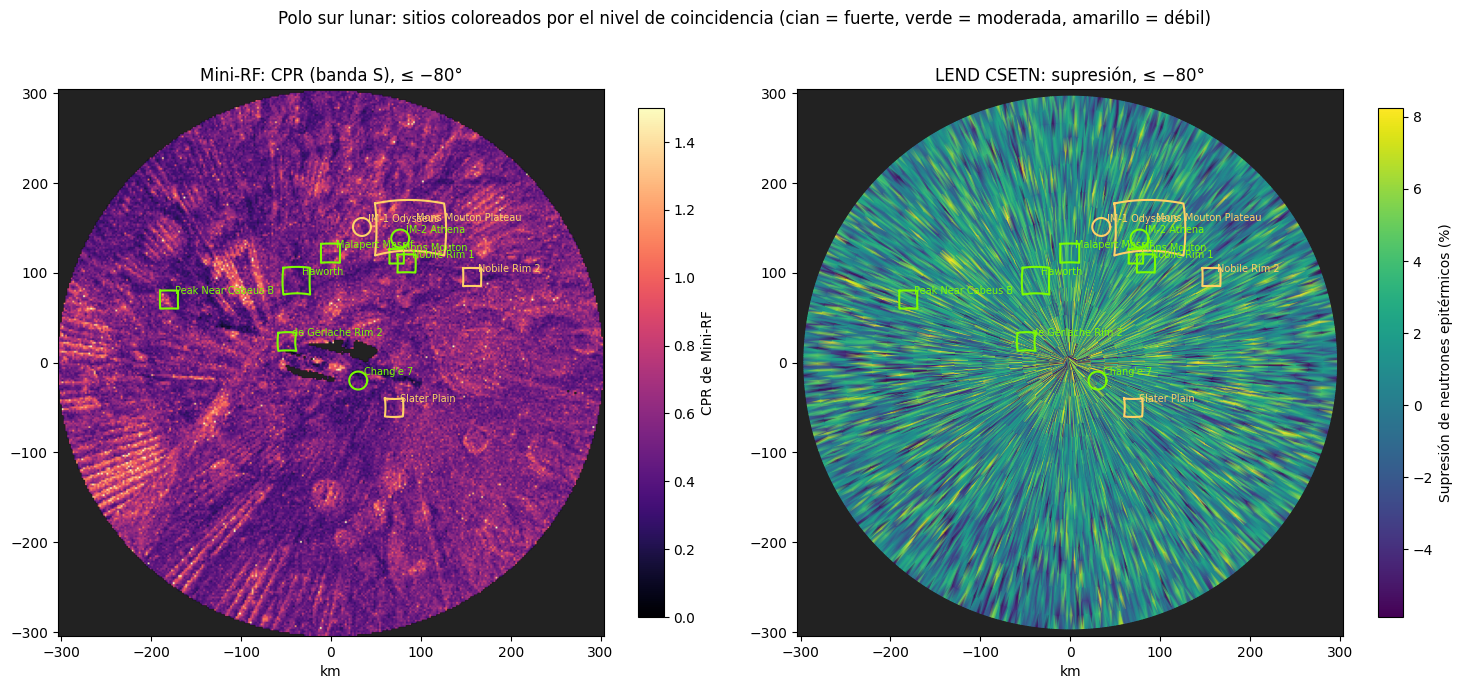

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 7))
lim = RHO_CASQUETE

# Mini-RF: media de CPR en celdas de 2 km
bins = np.arange(-lim, lim + 2, 2)
suma, _, _ = np.histogram2d(px_x, px_y, bins=[bins, bins], weights=px_v)
cuenta, _, _ = np.histogram2d(px_x, px_y, bins=[bins, bins])
with np.errstate(invalid="ignore"):
    media = suma / cuenta
im = ejes[0].imshow(media.T, origin="lower", extent=[-lim, lim, -lim, lim], cmap="magma", vmin=0, vmax=1.5)
plt.colorbar(im, ax=ejes[0], shrink=0.8, label="CPR de Mini-RF")
ejes[0].set_title("Mini-RF: CPR (banda S), ≤ −80°")

# LEND: supresión por celda, interpolada sobre una malla de triángulos entre los centros de las celdas
sc = ejes[1].tripcolor(lend["x"], lend["y"], lend["sup"] * 100, shading="gouraud", cmap="viridis",
                       vmin=np.percentile(lend["sup"] * 100, 2), vmax=np.percentile(lend["sup"] * 100, 98))
plt.colorbar(sc, ax=ejes[1], shrink=0.8, label="Supresión de neutrones epitérmicos (%)")
ejes[1].set_title("LEND CSETN: supresión, ≤ −80°")

colores = {"fuerte": "#00e5ff", "moderada": "#7CFC00", "débil": "#ffd166", "sin señal": "#ffffff"}


def contorno(geom):
    # Contorno exterior (si la geometría quedó partida en varias piezas, el de la mayor)
    if geom.geom_type == "MultiPolygon":
        geom = max(geom.geoms, key=lambda g: g.area)
    return geom.exterior.xy


for ax in ejes:
    for _, s in sitios.iterrows():
        x, y = contorno(s.geom)
        ax.plot(x, y, color=colores[s.nivel], lw=1.5)
        ax.annotate(s.nombre, (s.cx, s.cy), fontsize=7, color=colores[s.nivel], xytext=(4, 4), textcoords="offset points")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("km")
    ax.set_facecolor("#222")
fig.suptitle("Polo sur lunar: sitios coloreados por el nivel de coincidencia (cian = fuerte, verde = moderada, amarillo = débil)")
plt.tight_layout()
fig.savefig(FIG / "mapa_minirf_lend_sitios.png", dpi=150)
plt.show()

In [17]:
# Zoom alrededor de cada sitio: CPR de Mini-RF (40 × 40 km)
n = len(sitios)
cols = 4
fig, ejes = plt.subplots(math.ceil(n / cols), cols, figsize=(4 * cols, 4 * math.ceil(n / cols)))
for ax, (_, s) in zip(np.ravel(ejes), sitios.iterrows()):
    m = (np.abs(px_x - s.cx) < 20) & (np.abs(px_y - s.cy) < 20)
    ax.scatter(px_x[m], px_y[m], c=px_v[m], s=6, cmap="magma", vmin=0, vmax=1.5)
    x, y = contorno(s.geom)
    ax.plot(x, y, color=colores[s.nivel], lw=2)
    ax.set_title(f"{s.nombre}\nCPR {s.minirf_cpr_mediana:.2f} (p{s.minirf_percentil:.0f}) · {s.nivel}", fontsize=9)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
for ax in np.ravel(ejes)[n:]:
    ax.axis("off")
plt.tight_layout()
fig.savefig(FIG / "zoom_minirf_sitios.png", dpi=130)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 8. Exportación

- CSV completo en `04_resultados/hielo_v1/`.
- JSON para la web en `06_web/hielo_v1/hielo_lro.json`, con la misma clave por sitio que `sitios_v0` (`sitio_id`),
  para que el backend lo una sin transformar nada.
- Registro de la ejecución (parámetros, fuentes y conteos), como en el resto de capas.

In [18]:
def limpio(v):
    # NaN -> None y tipos de numpy -> tipos de Python, para que el JSON sea válido
    if isinstance(v, (np.floating, float)):
        return None if not np.isfinite(v) else round(float(v), 4)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.bool_,)):
        return bool(v)
    return v


columnas_csv = [
    "sitio_id", "nombre", "tipo", "lat", "lon", "area_km2",
    "diviner_f_hielo", "diviner_prof_hielo",
    "minirf_cpr_mediana", "minirf_cpr_p90", "minirf_frac_cpr_gt1", "minirf_cpr_anillo", "minirf_contraste",
    "minirf_percentil", "minirf_n_px",
    "lend_supresion", "lend_err", "lend_z", "lend_percentil", "lend_n_celdas",
    "senal_diviner", "senal_minirf", "senal_lend", "n_senales", "nivel",
    "pareja_hielo_tierra", "analogo_hielo_terreno_v0",
]
sitios[columnas_csv].to_csv(RES / "hielo_lro_sitios.csv", index=False)

fuentes = [
    {"instrumento": "Diviner PRP", "producto": "LRO-L-DLRE (vía hielo_v0)", "url": "https://pds-geosciences.wustl.edu/missions/lro/diviner.htm"},
    {"instrumento": "Mini-RF", "producto": "LRO-L-MRFLRO-5-GLOBAL-MOSAIC-V1.0, CPR 32 ppd", "url": URL_MINIRF_CPR},
    {"instrumento": "LEND", "producto": "LRO-L-LEND-4/5-RDR-V1.0, ALD polo sur", "url": LEND_DATA},
]
web = {
    "version": "hielo_v1",
    "generado": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "descripcion": "Hielo en los sitios del polo sur lunar con tres instrumentos de LRO: Diviner (frío), Mini-RF (radar) y LEND (hidrógeno).",
    "unidades": {
        "diviner_f_hielo": "fracción del sitio con hielo estable cerca de la superficie (0–1)",
        "minirf_cpr_mediana": "CPR mediano del sitio (banda S; adimensional)",
        "minirf_frac_cpr_gt1": "fracción del sitio con CPR > 1",
        "minirf_percentil": "percentil del CPR del sitio frente a 2000 discos al azar del casquete ≤ −80°",
        "lend_supresion": "supresión de neutrones epitérmicos CSETN frente a 55–60° S (0–1; sin restar el fondo de la nave)",
        "lend_z": "supresión / error estadístico",
        "lend_percentil": "percentil de la supresión frente a 2000 discos al azar del casquete ≤ −80°",
        "n_senales": "instrumentos que apuntan a hielo (0–3)",
    },
    "umbrales": {"diviner_f_hielo": UMBRAL_HIELO, "percentil_senal": PCT_SENAL, "lend_z": Z_LEND},
    "parametros": {"radio_punto_km": RADIO_PUNTO_KM, "radio_lend_km": RADIO_LEND_KM, "lat_casquete": LAT_CASQUETE, "n_discos_azar": N_DISCOS_AZAR},
    "sitios": {
        s["sitio_id"]: {k: limpio(s[k]) for k in columnas_csv if k != "sitio_id"}
        for _, s in sitios.iterrows()
    },
    "fuentes": fuentes,
    "nota": "Unir con 06_web/sitios_v0/sitios.geojson por id. La supresión de LEND solo sirve para comparar sitios entre sí.",
}
(WEB / "hielo_v1" / "hielo_lro.json").write_text(json.dumps(web, ensure_ascii=False, indent=1), encoding="utf-8")

registro = {
    "notebook": "hielo_v1.ipynb",
    "ejecutado": web["generado"],
    "parametros": web["parametros"] | web["umbrales"],
    "fuentes": fuentes,
    "conteos": {
        "sitios": int(len(sitios)),
        "niveles": sitios["nivel"].value_counts().to_dict(),
        "pixeles_minirf": int(len(px_v)),
        "celdas_lend": int(len(lend)),
    },
}
(RES / "registro_hielo_v1.json").write_text(json.dumps(registro, ensure_ascii=False, indent=1), encoding="utf-8")

if ACTUALIZAR_MANIFEST:
    ruta_m = WEB / "manifest.json"
    manifest = json.loads(ruta_m.read_text(encoding="utf-8"))
    manifest.setdefault("capas", {})["hielo_lro"] = {"version": "hielo_v1", "carpeta": "hielo_v1", "archivo": "hielo_v1/hielo_lro.json"}
    ruta_m.write_text(json.dumps(manifest, ensure_ascii=False, indent=1), encoding="utf-8")
    print("Capa «hielo_lro» registrada en manifest.json")

print("Escrito:", RES / "hielo_lro_sitios.csv", "·", WEB / "hielo_v1" / "hielo_lro.json")

Capa «hielo_lro» registrada en manifest.json
Escrito: /content/drive/MyDrive/Hackathon Nasa/04_resultados/hielo_v1/hielo_lro_sitios.csv · /content/drive/MyDrive/Hackathon Nasa/06_web/hielo_v1/hielo_lro.json


## 9. Limitaciones (conocidas antes de ejecutar)

- **Mini-RF no distingue hielo de rugosidad.** Un CPR alto en un sitio con hielo estable es compatible con hielo,
  pero también con un terreno lleno de bloques. Por eso solo cuenta como señal junto a las otras pruebas, y por eso
  miramos el contraste con el anillo de alrededor. Hay un debate abierto en la literatura sobre esto
  (p. ej., Spudis et al. 2013 frente a Fa y Eke 2018).
- **Mini-RF mira de lado** (~48° de incidencia) y su mosaico global no está controlado geodésicamente: puede estar
  desplazado ~1–2 km respecto a LOLA. A 10 km de radio no cambia el resultado, pero no sirve para cráteres pequeños.
- **LEND tiene poca resolución y mucho fondo.** Su mancha en el suelo es de ~10–20 km y más de la mitad de lo que cuenta
  CSETN son neutrones generados por la propia nave. No convertimos la supresión a porcentaje de hielo.
- **Profundidades distintas.** Diviner habla del primer metro (estabilidad térmica), Mini-RF ve hasta ~1 m en banda S
  y LEND el primer metro aproximadamente. Coinciden en orden de magnitud, no exactamente.
- **Pocos sitios.** 12 sitios polares: las correlaciones son orientativas.
- **No hay sitios al norte de −80°** en este análisis (la rejilla polar de LEND empieza en −80°).

## 10. Conclusiones (ejecución del 14 nov 2026, 13:32 UTC)

**Resumen en una frase:** ningún sitio del polo sur tiene las tres pruebas a la vez. Diviner (frío) y LEND (hidrógeno) coinciden de forma modesta en 6–8 sitios, y Mini-RF no aporta pruebas de hielo a esta escala: lo que mide es rugosidad.

### Resultados

1. **Niveles:** 0 fuerte, 8 moderada y 4 débil. Siete de los ocho «moderada» son Diviner + LEND. El octavo es Malapert Massif (Mini-RF + LEND), pero su Mini-RF es rugosidad (ver punto 3).

2. **Todo el polo tiene menos neutrones que las latitudes medias.** La supresión mediana de los 2000 discos al azar es de **+1,0 %**: el casquete entero está enriquecido en hidrógeno. Por eso el `lend_z` de la tabla, que compara con 55–60° S, sale ≥ 2 en casi todos los sitios y no discrimina. La pregunta útil es si un sitio tiene **más hidrógeno que el resto del polo**. Medido como (supresión − 1,0 %) / error:
   - Por encima de 2σ: **de Gerlache Rim 2 (2,6σ), IM-2 Athena (2,4σ), Nobile Rim 1 (2,3σ), Haworth (2,2σ), Malapert Massif (2,1σ) y Mons Mouton (2,1σ)**.
   - Entre 1σ y 2σ: Chang'e 7 (1,8σ), Slater Plain (1,4σ) y Peak Near Cabeus B (1,1σ).
   - Sin exceso: **IM-1 Odysseus (−0,1σ)**, Nobile Rim 2 (−0,1σ) y Mons Mouton Plateau (0,4σ).
   - Ojo: este error solo cubre el ruido de conteo (que sí es independiente entre celdas, porque cada una cuenta neutrones distintos). No incluye los errores sistemáticos (fondo de la nave, altura de la órbita, deriva de los detectores), así que un exceso de ~2σ es un indicio, no una detección. La v1.1 exige además el percentil frente al polo, que sí los recoge.

3. **Mini-RF mide rugosidad, no hielo.** Ningún sitio pasa del 8 % de píxeles con CPR > 1. Los dos con señal de Mini-RF (Malapert Massif, p84; Mons Mouton Plateau, p76) son los que menos hielo estable tienen según Diviner (0,21 y 0,19). En el mapa, el CPR alto sigue los bordes de cráteres y las laderas, no los fondos fríos. La prueba más clara: **cuanto más hielo estable tiene un sitio según Diviner, menos píxeles con CPR > 1 tiene** (Spearman ρ = −0,73, p = 0,007, n = 12). Los fondos fríos son lisos; los bordes y los macizos, rugosos y más templados. Coincide con lo que se discute en la literatura sobre el CPR en los polos (Eke et al., 2014: «Lunar polar craters — icy, rough or just sloping?»).

4. **Los instrumentos no ordenan los sitios igual.** Diviner vs LEND ρ = −0,08; Mini-RF vs LEND ρ = +0,08. Hay una razón de escala: Diviner mide la fracción de trampas frías a escala de cientos de metros dentro del sitio, mientras que LEND promedia ~20 km y no puede separar una trampa fría de su entorno.

### Parejas de hielo de `hielo_v0`

| Pareja | Diviner | LEND (exceso sobre el polo) | Mini-RF | Veredicto |
|---|---|---|---|---|
| **Nobile Rim 1 ↔ Pamir (Alto Badajshán)** | 0,35 | 2,3σ (p89) | p61, neutro | **Reforzada**: frío + algo más de hidrógeno que el resto del polo |
| **IM-2 Athena ↔ Askja** | 0,45 | 2,4σ (p90) | p41, neutro | **Reforzada** |
| **IM-1 Odysseus ↔ Axel Heiberg** | 0,97 (el máximo) | −0,1σ (p46) | p65, neutro | **Debilitada**: hace frío suficiente para el hielo, pero LEND no ve más hidrógeno que en el resto del polo |

La lección de IM-1: **que el hielo sea estable no significa que esté**. Diviner dice dónde *podría* conservarse; LEND, dónde hay hidrógeno de verdad.

### Qué región Artemis queda mejor respaldada para el uso «agua, hielo y permafrost» (enfoque D)

1. **Haworth**: la mayor fracción de hielo estable de las regiones Artemis (0,62) y exceso de hidrógeno de 2,2σ, con el menor error de todos (más celdas de LEND).
2. **Nobile Rim 1** y **Mons Mouton**: frío moderado (0,35–0,47) y exceso de ~2σ.
3. **de Gerlache Rim 2**: el mayor exceso de LEND (2,6σ), pero con poco hielo estable (0,26) y con un hueco de datos de Mini-RF en el propio sitio.

Slater Plain tiene mucho frío (0,54) pero poco exceso de hidrógeno (1,4σ); Malapert Massif y Mons Mouton Plateau son los menos favorables para el hielo.

### Qué cambia en el proyecto

- **La ficha y el pitch: dónde falla la analogía.** Los análogos de hielo de la Tierra (Pamir, Axel Heiberg, Askja) tienen hielo masivo en el suelo. En la Luna, la señal de LEND indica hidrógeno **escaso y repartido**: unos pocos puntos de supresión en zonas de 20 km. Incluso en el punto más rico del polo sur (el cráter Cabeus, donde impactó LCROSS) la estimación de LEND es de 0,5–4 % de hielo en peso (Mitrofanov et al., 2010). La analogía funciona para la **temperatura y la estabilidad** del hielo; **falla en la cantidad y la forma** (hielo masivo frente a granos mezclados con el regolito).
- **Mensaje fuerte para el pitch:** contrastamos tres instrumentos independientes de LRO en vez de fiarnos de uno, y eso cambió una conclusión (IM-1 ↔ Axel Heiberg pierde fuerza).
- **Mini-RF tiene otro uso:** como no sirve para el hielo aquí, sirve como **indicador de rugosidad a escala decimétrica** para el uso «aterrizaje y movilidad». Malapert Massif y Mons Mouton Plateau son las regiones más rugosas para el radar.
- El nivel de la capa `hielo_lro` en la API debe leerse junto con estas conclusiones: «moderada» casi siempre significa «Diviner + un exceso modesto de LEND».

### Pendiente (hielo v1.1)

- Cambiar la señal de LEND: exceso sobre la mediana del polo ≥ 2σ, en vez de percentil ≥ 75 y `lend_z` frente a latitudes medias. Con esa regla, Chang'e 7 y Peak Near Cabeus B pasan de «moderada» a «débil».
- Exigir a LEND, además del exceso ≥ 2σ, el percentil ≥ 75 frente a los discos al azar (recoge los errores sistemáticos) y probar la sensibilidad al radio (15, 20 y 30 km). Hecho en `hielo_v1.1`.
- Guardar la fracción de CPR > 1 como `rugosidad_radar` para el uso de aterrizaje.
- Cosméticos: suavizar el mapa de LEND (las rayas radiales salen de interpolar celdas muy estrechas cerca del polo) y ampliar el zoom de Mons Mouton Plateau, que es más grande que la ventana de 40 km.
- Sincronizar `06_web/hielo_v1` con el backend y actualizar la bibliografía de Drive.

**Referencias:** Mitrofanov et al. (2010), *Science* 330, 483–486 · Eke et al. (2014), *Icarus* · Spudis et al. (2013), *JGR Planets* · Datos: LRO Mini-RF, LEND y Diviner (PDS Geosciences).